# Case 2: experiment read-out on the Upworthy Research Archive

Reads `results/case2.json` written by `analysis.py`, runs the selection query live, and shows the
sequential looks and the figures. The memo is `memo.md`, the selection rule is in `README.md`.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

from product_analytics_cases.common import CASES, RESULTS, connect, run_sql

HERE = CASES / "02_experiment_readout"
res = json.loads((RESULTS / "case2.json").read_text(encoding="utf-8"))
numbers = pd.DataFrame([{"key": k, **v} for k, v in res["numbers"].items()]).set_index("key")
numbers

,value,source,unit
key,,,
rows_read,128217,sql/rows_read.sql,
exploratory_tests,4862,sql/qualifying_arms.sql + test_summary() + lif...,
exploratory_qualifying,4862,sql/candidate_count.sql,
exploratory_two_arm,127,sql/candidate_count.sql,
exploratory_rule_candidates,55,sql/candidate_count.sql,
...,...,...,...
curse_mean_lift_second_half_pct,21.493002,sql/qualifying_arms.sql + winners_curse(),%
curse_median_lift_first_half_pct,21.47272,sql/qualifying_arms.sql + winners_curse(),%
curse_median_lift_second_half_pct,5.986624,sql/qualifying_arms.sql + winners_curse(),%


## The worked example, selected by the pre-registered rule

In [2]:
con = connect("upworthy")
run_sql(con, HERE, "worked_example.sql")

,test_id,test_week,created_at,arm_rank,headline,eyecatcher_id,impressions,clicks,ctr
0,52447209aadb065894000a68,201338,2013-09-26 17:43:55.289,1,Miley Cyrus Points Out Something Wrong With Am...,5332c0561fae79f09f00ca24,13921,883,0.063429
1,52447209aadb065894000a68,201338,2013-09-26 17:45:52.381,2,IMAGE: Miley Cyrus Points Out Something Wrong ...,5332c0561fae79f09f00ca24,14253,829,0.058163


In [3]:
print(Path(HERE / "sql" / "worked_example.sql").read_text(encoding="utf-8"))

-- The pre-registered selection rule from README.md: among exploratory tests with exactly two arms,
-- the same eyecatcher_id on both arms (no image change), different headlines and at least 1,000
-- impressions per arm, take the test with the most total impressions. Ties go to the lower test id.
WITH t AS (
    SELECT
        clickability_test_id AS test_id,
        COUNT(*) AS arms,
        COUNT(DISTINCT eyecatcher_id) AS images,
        COUNT(DISTINCT headline) AS headlines,
        MIN(impressions) AS min_impressions,
        SUM(impressions) AS total_impressions
    FROM exploratory
    GROUP BY 1
), chosen AS (
    SELECT test_id
    FROM t
    WHERE arms = 2 AND images = 1 AND headlines = 2 AND min_impressions >= 1000
    ORDER BY total_impressions DESC, test_id
    LIMIT 1
)
SELECT
    e.clickability_test_id AS test_id,
    e.test_week,
    e.created_at,
    ROW_NUMBER() OVER (ORDER BY e.created_at, e.headline) AS arm_rank,
    e.headline,
    e.eyecatcher_id,
    e.impression

## Group-sequential looks on the reconstructed stream

In [4]:
t = res["tables"]["we_obf_looks"]
pd.DataFrame(t["rows"], columns=t["columns"]).round(3)

,look,impressions,z,boundary,crossed
0,1,5635,-0.925,4.383,False
1,2,11270,-2.693,3.099,False
2,3,16904,-3.164,2.556,True
3,4,22539,-2.602,2.253,True
4,5,28174,-1.850,2.065,False


worked_example_sequential from sequential.reconstruct_stream() + plot_worked_example()


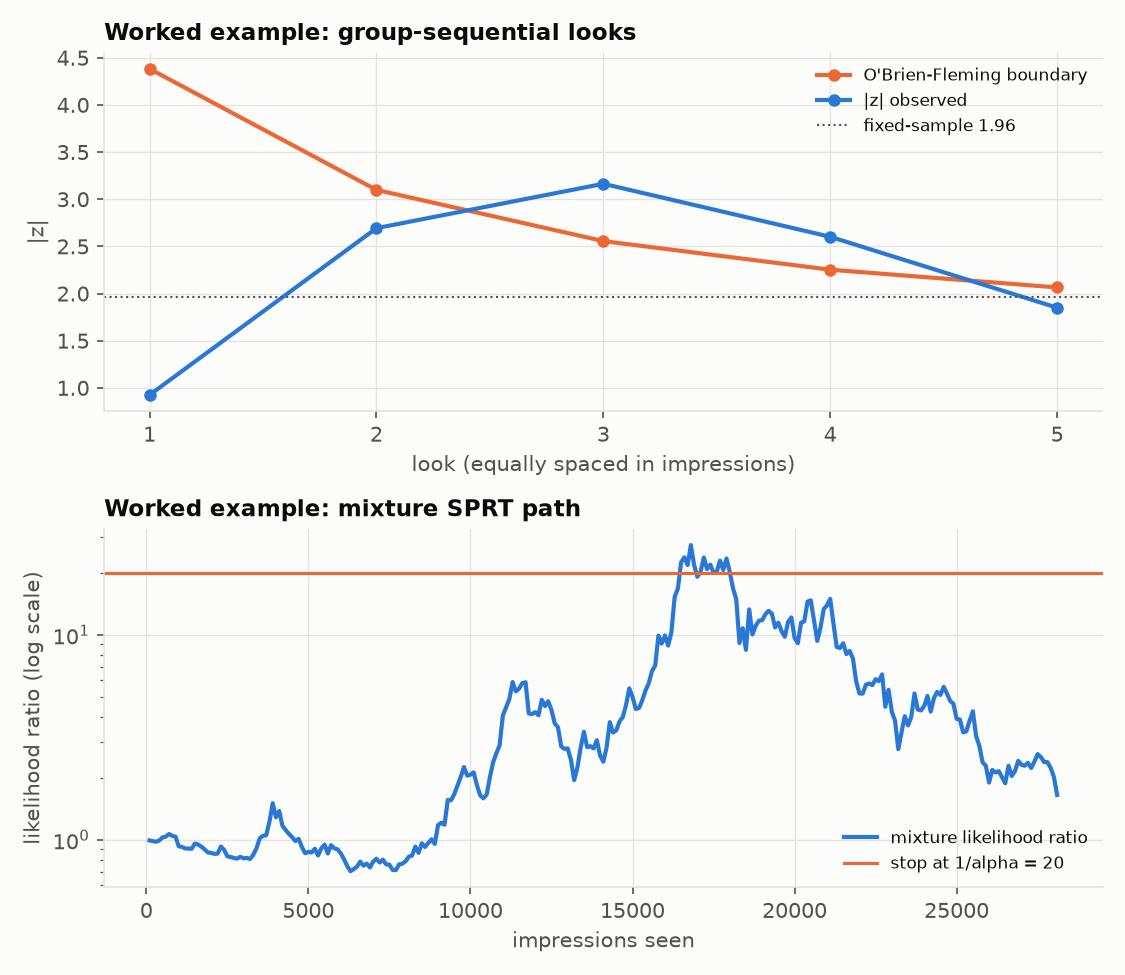

lift_distribution from test_summary() + plot_lifts()


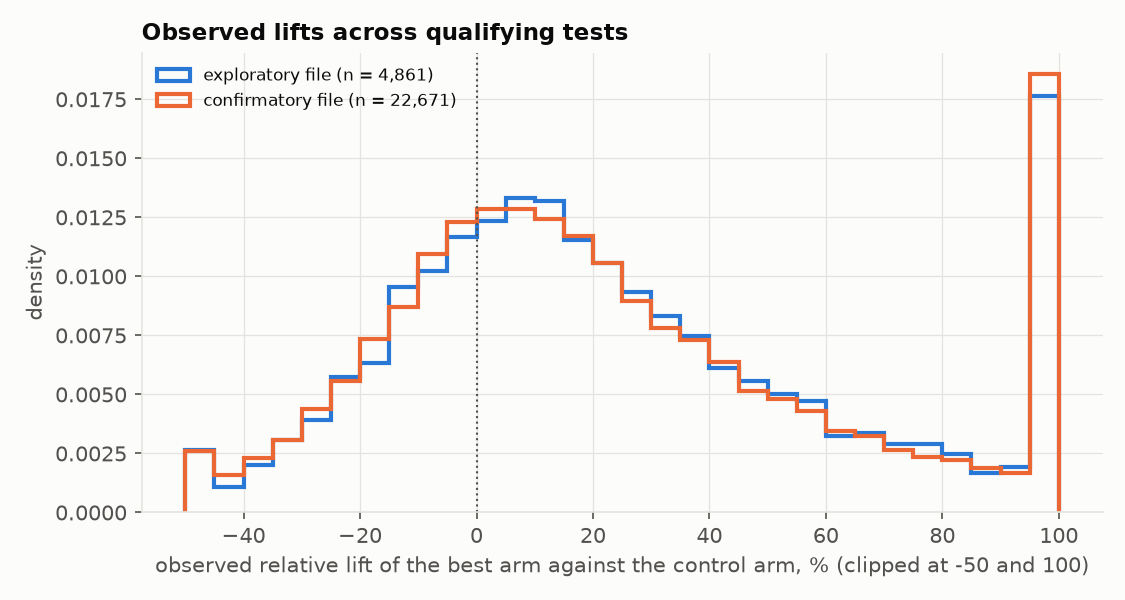

false_positive_rates from sequential.null_false_positive_rates() + plot_fpr()


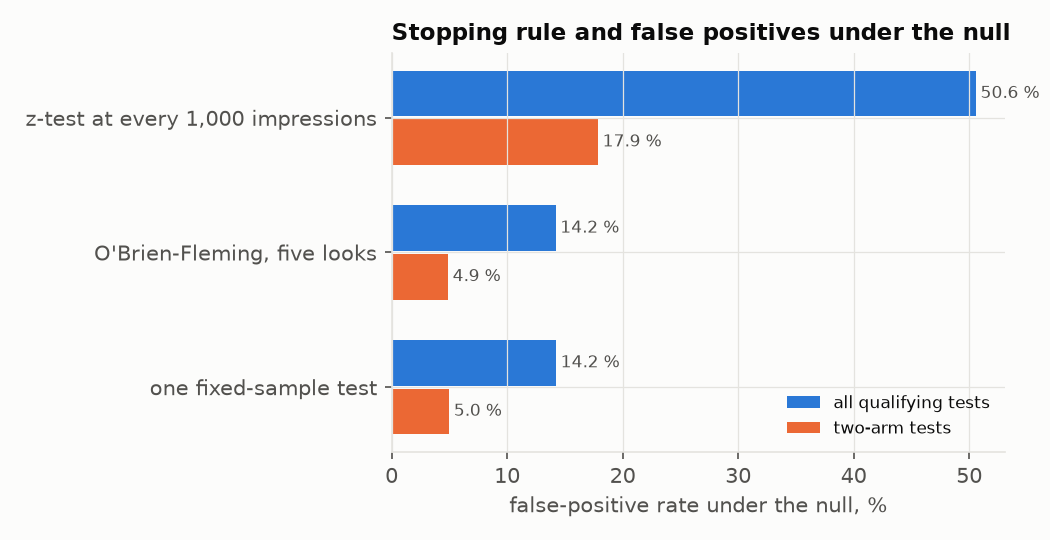

In [5]:
for key, fig in res["figures"].items():
    print(key, "from", fig["source"])
    display(Image(filename=str(RESULTS.parent / fig["file"])))